# Phần 2b — Inverting Gradients trên LeNet (CIFAR-10), để so sánh công bằng với Phần 1 & Phần 3

**Pillar:** Security — privacy trong Federated Learning (FL).

**Vì sao notebook này tồn tại.** Phần 1 (DLG/iDLG) và Phần 3 (R-GAP) đều tấn công một LeNet nhỏ trên CIFAR-10,
nhưng Phần 2 (Inverting Gradients) lại chạy trên ResNet-18/ImageNet — khác kiến trúc, khác dataset, khác lưới
DP-SGD tuyệt đối. Notebook này chạy **lại đúng thuật toán Inverting Gradients** của Phần 2, nhưng trên **đúng
LeNet + đúng ảnh CIFAR-10 (img\_index = 17) + đúng weights\_init + đúng seed** của Phần 1, và dùng **đúng lưới
DP-SGD** ($C/\lVert g\rVert = 0.5, 1.0$; $\sigma \in \{0, 10^{-4}, 10^{-3}, 10^{-2}\}$) mà Phần 1 & Phần 2
đã dùng. Mục tiêu: có một điểm so sánh thật sự táo-với-táo giữa DLG, iDLG, Inverting Gradients và R-GAP — cùng
kiến trúc, cùng ảnh, cùng ngân sách defense — việc mà cấu trúc hiện tại của báo cáo còn thiếu.

**Model:** `LeNet` y hệt Phần 1 (4 khối Conv + Sigmoid, đầu ra 10 lớp, có bias). **Dataset:** CIFAR-10, ảnh
`img_index = 17` — đúng ảnh Phần 1 dùng. **Attack:** `inversefed.GradientReconstructor` (cosine cost + TV prior +
signed Adam), y hệt Phần 2 mục 4, chỉ đổi `img_shape`, `mean_std` cho phù hợp LeNet/CIFAR-10 thay vì ResNet-18/ImageNet.

In [1]:
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

## 1. Imports, dataset CIFAR-10 và victim LeNet (y hệt Phần 1)

Toàn bộ cell dưới đây — imports, `torch.manual_seed(50)`, dataset CIFAR-10, định nghĩa `LeNet`, `weights_init` —
được copy nguyên văn từ `part1_dlg_lenet/part1.ipynb` theo đúng thứ tự, để trọng số khởi tạo của `net` **giống hệt
bit-for-bit** với Phần 1 (cùng seed, cùng thứ tự gọi RNG). Nhờ vậy gradient `input_gradient` thu được dưới đây có
cùng norm với gradient Phần 1 đã dùng, nên lưới $(C,\sigma)$ tính theo tỉ lệ $C/\lVert g\rVert$ cho ra cùng ngưỡng
clip tuyệt đối.

In [2]:
import numpy as np
from pprint import pprint

from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
torch.manual_seed(50)

import inversefed

print(torch.__version__, torchvision.__version__)

2.10.0+cu128 0.25.0+cu128


In [3]:
dst = datasets.CIFAR10("../part1_dlg_lenet/data")
tp = transforms.Compose([
    transforms.Resize(32),
    transforms.CenterCrop(32),
    transforms.ToTensor()
])
tt = transforms.ToPILImage()

setup = inversefed.utils.system_startup()
device = setup['device']
print("Running on %s" % device)

# raw [0,1] pixels (no normalization), like Part 1 -- GradientReconstructor needs
# actual tensors here (not plain floats), its box-constraint code calls torch.min(x, (1-dm)/ds).
dm = torch.zeros(3, 1, 1, **setup)
ds = torch.ones(3, 1, 1, **setup)

Currently evaluating -------------------------------:
Wednesday, 14. October 2026 02:31PM
CPUs: 10, GPUs: 1 on DESKTOP-DF030H0.
GPU : NVIDIA GeForce RTX 5060 Ti
Running on cuda:0


In [4]:
def weights_init(m):
    if hasattr(m, "weight"):
        m.weight.data.uniform_(-0.5, 0.5)
    if hasattr(m, "bias"):
        m.bias.data.uniform_(-0.5, 0.5)

class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        act = nn.Sigmoid
        self.body = nn.Sequential(
            nn.Conv2d(3, 12, kernel_size=5, padding=5//2, stride=2),
            act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=5//2, stride=2),
            act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=5//2, stride=1),
            act(),
            nn.Conv2d(12, 12, kernel_size=5, padding=5//2, stride=1),
            act(),
        )
        self.fc = nn.Sequential(
            nn.Linear(768, 10)
        )

    def forward(self, x):
        out = self.body(x)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

net = LeNet().to(**setup)
net.apply(weights_init)

LeNet(
  (body): Sequential(
    (0): Conv2d(3, 12, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): Sigmoid()
    (2): Conv2d(12, 12, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (3): Sigmoid()
    (4): Conv2d(12, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (5): Sigmoid()
    (6): Conv2d(12, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (7): Sigmoid()
  )
  (fc): Sequential(
    (0): Linear(in_features=768, out_features=10, bias=True)
  )
)

## 2. Gradient của client

Client tính gradient cục bộ trên ảnh private $(x,y)$ với cross-entropy chuẩn (tích hợp sẵn trong
`inversefed.GradientReconstructor`, không cần soft-label như DLG ở Phần 1) rồi gửi `input_gradient` cho server.
`img_index = 17` — đúng ảnh Phần 1 đã dùng.

GT label is 3 (cat).


Full gradient norm is 5.856183e+00.


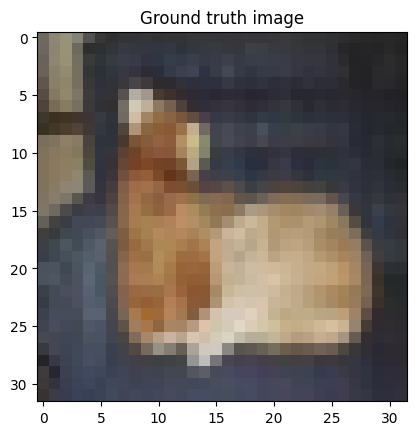

In [5]:
img_index = 17
gt_data = tp(dst[img_index][0]).to(**setup)
gt_data = gt_data.view(1, *gt_data.size())
gt_label = torch.as_tensor((dst[img_index][1],), device=setup['device'])

plt.imshow(tt(gt_data[0].cpu()))
plt.title("Ground truth image")
print("GT label is %d (%s)." % (gt_label.item(), dst.classes[gt_label.item()]))

net.zero_grad()
target_loss = F.cross_entropy(net(gt_data), gt_label)
input_gradient = torch.autograd.grad(target_loss, net.parameters())
input_gradient = [grad.detach().clone() for grad in input_gradient]
full_norm = torch.stack([g.norm() for g in input_gradient]).mean()
print("Full gradient norm is %e." % full_norm)

## 3. Inverting Gradients — reconstruct ảnh từ gradient

Cùng `config` và cùng thuật toán với Phần 2 mục 4 (cosine cost, TV prior, signed Adam, box constraint, median
filter, lr decay, nhiều restart) — chỉ khác `img_shape = (3, 32, 32)` (thay vì $224\times224$) và
`mean_std = (0.0, 1.0)` vì ảnh CIFAR-10 ở đây dùng pixel thô $[0,1]$ (giống Phần 1), không normalize theo
ImageNet mean/std như Phần 2. LeNet nhỏ hơn ResNet-18 rất nhiều nên cùng ngân sách iteration chạy nhanh hơn
đáng kể.

In [6]:
config = dict(signed=True,
              boxed=True,
              cost_fn='sim',
              indices='top10',
              weights='equal',
              lr=0.1,
              optim='adam',
              restarts=2,
              max_iterations=24_000,
              total_variation=1e-6,
              init='randn',
              filter='median',
              lr_decay=True,
              scoring_choice='loss')

rec_machine = inversefed.GradientReconstructor(net, (dm, ds), config, num_images=1)
output, stats = rec_machine.reconstruct(input_gradient, gt_label, img_shape=(3, 32, 32))

test_mse = (output.detach() - gt_data).pow(2).mean()
feat_mse = (net(output.detach()) - net(gt_data)).pow(2).mean()
test_psnr = inversefed.metrics.psnr(output, gt_data, factor=1.0)

print("Rec. loss: %2.4f | MSE: %2.4f | PSNR: %4.2f dB | FMSE: %2.4e" %
      (stats['opt'], test_mse, test_psnr, feat_mse))

It: 0. Rec. loss: 0.0688.


It: 500. Rec. loss: 0.0026.


It: 1000. Rec. loss: 0.0025.


It: 1500. Rec. loss: 0.0026.


It: 2000. Rec. loss: 0.0019.


...

It: 22500. Rec. loss: 0.0002.


It: 23000. Rec. loss: 0.0002.


It: 23500. Rec. loss: 0.0002.


It: 23999. Rec. loss: 0.0000.
Choosing optimal result ...
Optimal result score: 0.0002
Total time: 532.3548924922943.
Rec. loss: 0.0002 | MSE: 0.0022 | PSNR: 26.48 dB | FMSE: 9.2923e-04


C:\Users\Admin\AppData\Local\Temp\ipykernel_17868\2046806465.py:23: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  print("Rec. loss: %2.4f | MSE: %2.4f | PSNR: %4.2f dB | FMSE: %2.4e" %


### Ground truth và ảnh reconstruct

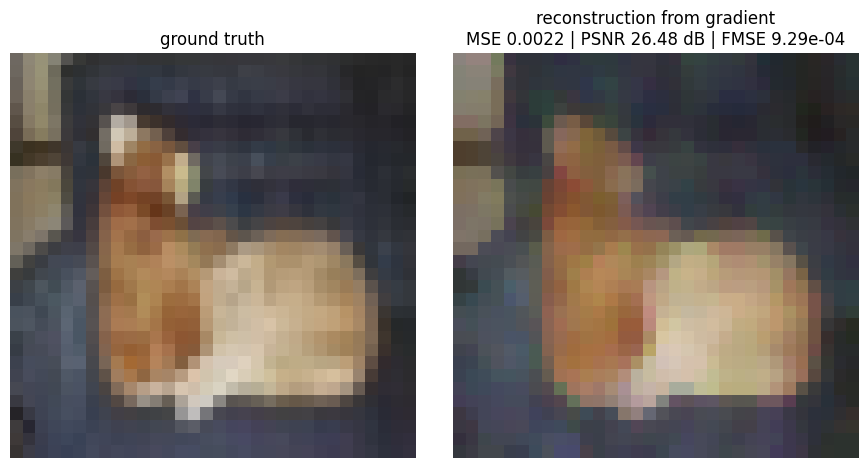

In [7]:
def to_img(tensor):
    return tensor.clone().detach().clamp(0, 1)[0].permute(1, 2, 0).cpu()

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
axes[0].imshow(to_img(gt_data)); axes[0].set_title("ground truth"); axes[0].axis("off")
axes[1].imshow(to_img(output)); axes[1].axis("off")
axes[1].set_title("reconstruction from gradient\nMSE %.4f | PSNR %.2f dB | FMSE %.2e" % (test_mse, test_psnr, feat_mse))
plt.tight_layout(); plt.show()

## 4. DP-SGD defense — cùng lưới $(C,\sigma)$ như Phần 1 & Phần 2

$$\tilde{g} = \mathrm{clip}(g, C) + \mathcal{N}\!\left(0,\; (\sigma C)^2 I\right), \qquad \mathrm{clip}(g, C) = g \cdot \min\!\left(1, \tfrac{C}{\lVert g\rVert_2}\right)$$

$C$ được đặt theo **đúng tỉ lệ** $C/\lVert g\rVert = 0.5$ và $1.0$ mà Phần 1 & Phần 2 đã dùng (vì `net` ở
đây có cùng trọng số khởi tạo với Phần 1 — xem mục 1 — nên $\lVert g\rVert$ ở hai notebook gần như bằng nhau,
và $C$ tuyệt đối ra cùng giá trị $\approx 10, 30$ như Phần 1). $\sigma \in \{0, 10^{-4}, 10^{-3}, 10^{-2}\}$ —
đúng dải Phần 1 & Phần 2 đã dùng. Giống Phần 2, `labels=None` nên attacker tự recover label bằng iDLG-trick từ
chính gradient đã bị defense (`label_correct` cho biết label đó có đúng không).

**Ngân sách tính toán.** `DEFENSE_ITERS = 4_800`, `DEFENSE_RESTARTS = 1` — đúng ngân sách Phần 2 mục 5 đã dùng
cho mỗi cấu hình trong lưới $2 \times 4 = 8$ cấu hình.

In [8]:
DEFENSE_ITERS, DEFENSE_RESTARTS = 4_800, 1
defense_config = dict(config, restarts=DEFENSE_RESTARTS, max_iterations=DEFENSE_ITERS)

def global_norm(grads):
    return torch.sqrt(sum((g ** 2).sum() for g in grads)).item()

def dp_sgd_defense(grads, C, sigma):
    coef = min(1.0, C / (global_norm(grads) + 1e-6))
    return [g * coef + torch.randn_like(g) * sigma * C for g in grads]

def grad_cosine(a, b):
    return (sum((x * y).sum() for x, y in zip(a, b)) / (global_norm(a) * global_norm(b))).item()

total_norm = global_norm(input_gradient)
clip_norms = [round(r * total_norm, 4) for r in (0.5, 1.0)]   # half-norm clip, and C = norm exactly (no clipping)
noise_stds = [0.0, 1e-4, 1e-3, 1e-2]                              # same sigma grid as Part 1 & 2
print("Global L2 norm of the original gradient: %.4f | clip norms C: %s" % (total_norm, clip_norms))

defense_results = []
for C in clip_norms:
    for sigma in noise_stds:
        defended = dp_sgd_defense(input_gradient, C, sigma)
        label_pred = torch.argmin(torch.sum(defended[-2], dim=-1), dim=-1)
        print("\n[%d/%d] C=%.4f, sigma=%.0e" % (len(defense_results) + 1, len(clip_norms) * len(noise_stds), C, sigma))

        rec_machine = inversefed.GradientReconstructor(net, (dm, ds), defense_config, num_images=1)
        out, st = rec_machine.reconstruct(defended, None, img_shape=(3, 32, 32))

        res = dict(clip_norm=C, noise_std=sigma, grad_cos=grad_cosine(defended, input_gradient),
                   label_correct=label_pred.item() == gt_label.item(), rec_loss=st['opt'],
                   mse=(out.detach() - gt_data).pow(2).mean().item(),
                   psnr=inversefed.metrics.psnr(out, gt_data, factor=1.0),
                   fmse=(net(out.detach()) - net(gt_data)).pow(2).mean().item(), image=out.detach().cpu())
        defense_results.append(res)
        print("   -> grad cos %.3f | label %s | MSE %.4f | PSNR %.2f dB | FMSE %.3e"
              % (res["grad_cos"], "correct" if res["label_correct"] else "WRONG", res["mse"], res["psnr"], res["fmse"]))

import pandas as pd
defense_df = pd.DataFrame(defense_results).drop(columns="image")
defense_df

Global L2 norm of the original gradient: 29.4433 | clip norms C: [14.7217, 29.4433]

[1/8] C=14.7217, sigma=0e+00
It: 0. Rec. loss: 0.0708.


It: 500. Rec. loss: 0.0034.


It: 1000. Rec. loss: 0.0019.


It: 1500. Rec. loss: 0.0021.


It: 2000. Rec. loss: 0.0013.


...

It: 3500. Rec. loss: 0.4145.


It: 4000. Rec. loss: 0.4164.


It: 4500. Rec. loss: 0.4131.


It: 4799. Rec. loss: 0.4087.
Choosing optimal result ...
Optimal result score: 0.4087
Total time: 54.326236963272095.
   -> grad cos 0.583 | label correct | MSE 0.0841 | PSNR 10.75 dB | FMSE 1.297e-01


,clip_norm,noise_std,grad_cos,label_correct,rec_loss,mse,psnr,fmse
0,14.7217,0.0000,1.000000,True,0.000008,0.001382,28.596363,0.000021
1,14.7217,0.0001,0.999903,True,0.000104,0.001756,27.554806,0.000032
2,14.7217,0.0010,0.990373,True,0.009499,0.014488,18.390015,0.001403
3,14.7217,0.0100,0.574508,True,0.416139,0.118514,9.262320,0.072102
4,29.4433,0.0000,1.000000,True,0.000009,0.001606,27.941847,0.000024
5,29.4433,0.0001,0.999902,True,0.000105,0.001853,27.320860,0.000051
6,29.4433,0.0010,0.990425,True,0.009438,0.018438,17.342922,0.003655
7,29.4433,0.0100,0.583294,True,0.408671,0.084079,10.753150,0.129724


### Chất lượng reconstruction theo noise level

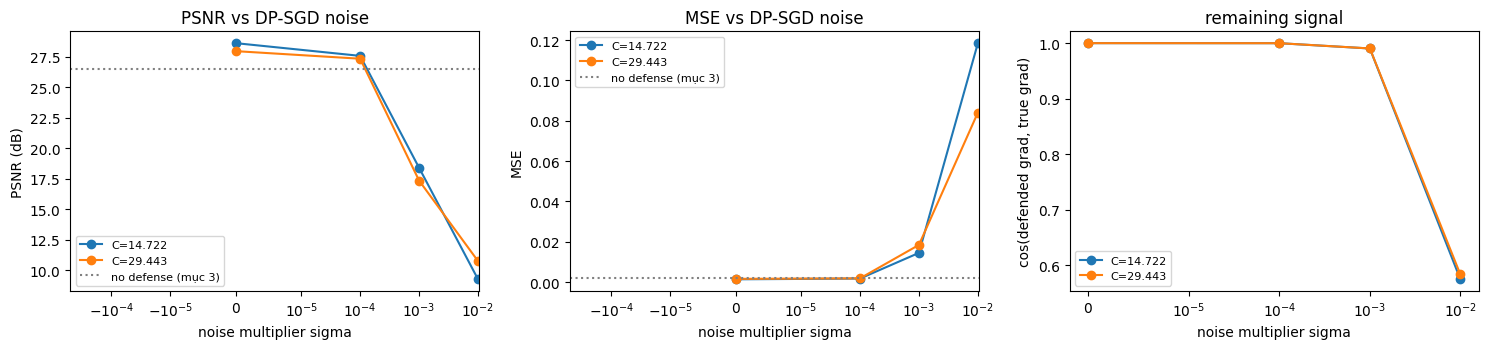

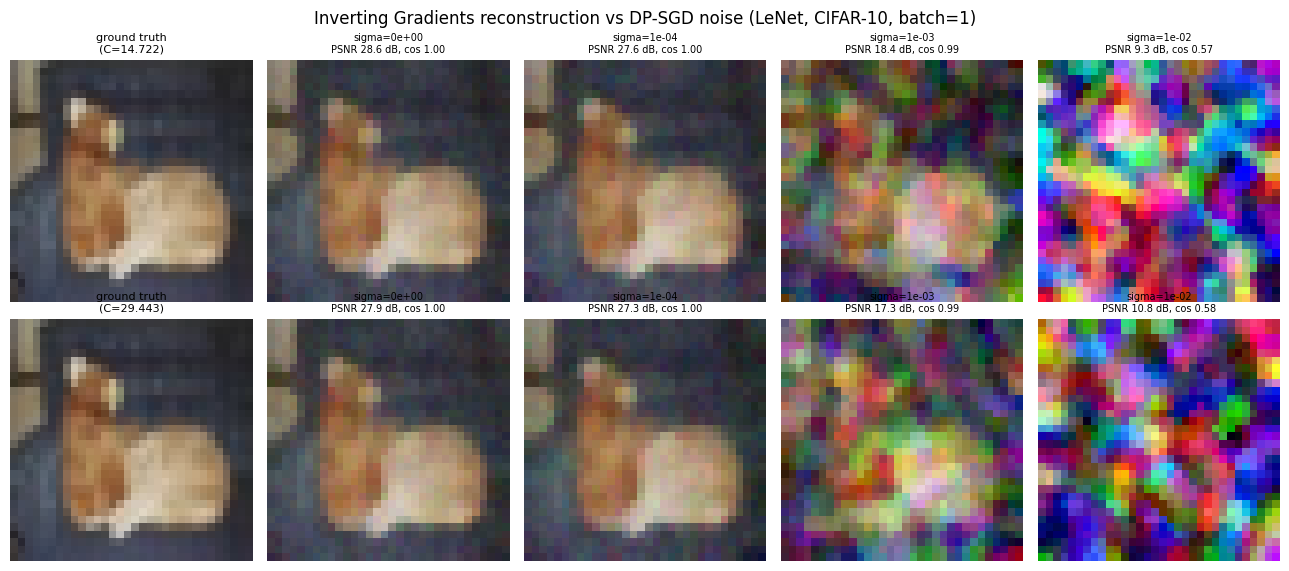

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for C, group in defense_df.groupby("clip_norm"):
    axes[0].plot(group["noise_std"], group["psnr"], marker="o", label="C=%.3f" % C)
    axes[1].plot(group["noise_std"], group["mse"], marker="o", label="C=%.3f" % C)
    axes[2].plot(group["noise_std"], group["grad_cos"], marker="o", label="C=%.3f" % C)
axes[0].axhline(float(test_psnr), color="gray", ls=":", label="no defense (mục 3)")
axes[1].axhline(float(test_mse), color="gray", ls=":", label="no defense (mục 3)")
axes[0].set_ylabel("PSNR (dB)"); axes[0].set_title("PSNR vs DP-SGD noise")
axes[1].set_ylabel("MSE"); axes[1].set_title("MSE vs DP-SGD noise")
axes[2].set_ylabel("cos(defended grad, true grad)"); axes[2].set_title("remaining signal")
for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-5); ax.set_xlabel("noise multiplier sigma"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(clip_norms), len(noise_stds) + 1, figsize=(2.6 * (len(noise_stds) + 1), 2.9 * len(clip_norms)))
for i, C in enumerate(clip_norms):
    axes[i, 0].imshow(to_img(gt_data)); axes[i, 0].set_title("ground truth\n(C=%.3f)" % C, fontsize=8)
    for j, r in enumerate([r for r in defense_results if r["clip_norm"] == C]):
        axes[i, j + 1].imshow(to_img(r["image"]))
        axes[i, j + 1].set_title("sigma=%.0e\nPSNR %.1f dB, cos %.2f" % (r["noise_std"], r["psnr"], r["grad_cos"]), fontsize=7)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Inverting Gradients reconstruction vs DP-SGD noise (LeNet, CIFAR-10, batch=1)")
plt.tight_layout(); plt.show()

### Kết luận

Với notebook này, cả ba họ attack — DLG/iDLG (`part1.ipynb` mục 6), Inverting Gradients (notebook này), và R-GAP
(`part3.ipynb` mục 9) — giờ đều có một điểm đối chiếu dưới **cùng kiến trúc LeNet, cùng ảnh CIFAR-10, cùng lưới
$(C,\sigma)$**. Chương Đánh giá thực nghiệm của báo cáo sẽ tổng hợp cả ba đường cong PSNR-vs-$\sigma$ này vào
một bảng/biểu đồ duy nhất.

In [10]:
import numpy as np, os
RAW_DIR = r"E:\Project\Trustworthy_AI_Project\final-report\raw"
os.makedirs(RAW_DIR, exist_ok=True)

gt_np = to_img(gt_data).numpy().astype(np.float32)
dpsgd_imgs = np.stack([to_img(r["image"]).numpy() for r in defense_results]).reshape(
    len(clip_norms), len(noise_stds), *gt_np.shape).astype(np.float32)
dpsgd_mse = np.array([r["mse"] for r in defense_results]).reshape(len(clip_norms), len(noise_stds))
dpsgd_psnr = np.array([r["psnr"] for r in defense_results]).reshape(len(clip_norms), len(noise_stds))

np.savez(os.path.join(RAW_DIR, "part2_lenet.npz"),
    gt=gt_np,
    recon=to_img(output).numpy().astype(np.float32),
    mse=float(test_mse),
    psnr=float(test_psnr),
    dpsgd_clip_norms=np.array(clip_norms),
    dpsgd_noise_stds=np.array(noise_stds),
    dpsgd_images=dpsgd_imgs,
    dpsgd_mse=dpsgd_mse,
    dpsgd_psnr=dpsgd_psnr,
)
print("saved", os.path.join(RAW_DIR, "part2_lenet.npz"))

saved E:\Project\Trustworthy_AI_Project\final-report\raw\part2_lenet.npz
